# Classification Models: From Binary Diagnosis to Multiclass Prediction

---

> ### 📋 Practice Exercise. Not Graded.
> This is a **practice assignment** for self-assessment. The marks shown throughout are **indicative only**. They tell you where to spend your effort and where you might need more practice. **None of these marks count towards your final grade.**
>
> Attempt every section. Compare your results. Revisit what trips you up.

---

## What You Will Build

Two classifiers, two datasets, one progression from simple to complex.

| Part | Dataset | Task | Primary Metric |
|------|---------|------|----------------|
| **Part 1** | Breast Cancer (sklearn) | Binary: Malignant vs Benign | Recall (Sensitivity) |
| **Part 2** | Wine (sklearn) | Multiclass: 3 wine cultivars | Macro-averaged F1-Score |

**Indicative Marks: 100** (Part 1: 55 | Part 2: 45)

### Before You Start
- Complete all cells marked with `# TODO`.
- Markdown cells marked **[Your Answer]** need written responses. Don't skip them.
- Run `Runtime > Restart and run all` before reviewing. The notebook should execute top to bottom without errors.
- Use `random_state=42` wherever a function accepts it. This keeps your results reproducible.


---
# PART 1: Binary Classification, Breast Cancer Prediction

## Context

Early detection of malignant tumours saves lives. In this part, you will build classifiers that predict whether a breast tumour is **malignant** or **benign** based on features computed from cell nuclei images.

**Why Recall matters here:** A false negative means telling a patient their tumour is benign when it is actually malignant. That is a missed cancer diagnosis. A false positive means an unnecessary follow-up test. Annoying, but survivable. The asymmetry is stark: we prioritise **recall for the malignant class** above everything else.

> **Clinical Constraint:** We want recall ≥ 0.95 for malignant cases, while keeping precision ≥ 0.60 (i.e., not flooding clinics with false alarms).


## Stage 1: Data and Package Loading

<font color="red">**[3 marks]**</font>

Load the Breast Cancer Wisconsin dataset from `sklearn.datasets`.

**What to do:**
- The libraries below are pre-imported. Review them, add anything else you need.
- Load the dataset using `load_breast_cancer()`
- Convert it to a DataFrame with proper column names
- Separate features (`X`) and target (`y`)

> **Watch out:** In the raw dataset, `0 = malignant` and `1 = benign`. Since `recall_score` defaults to `pos_label=1`, we need malignant to be 1. **Remap the target** with `y = 1 - data.target`.


In [162]:
# Pre-imported libraries. Review these, add what you need below.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')


In [163]:
# Load the breast cancer dataset and convert to DataFrame
data = load_breast_cancer(as_frame=True)
bc_df = data.frame
bc_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [164]:
# Separate features and target, remap so malignant = 1
X = bc_df.drop(columns=['target'])
y = 1 - data.target
type(y)


pandas.core.series.Series

## Stage 2: Data Understanding

<font color="red">**[8 marks]**</font>

Before building any model, understand the data.


### 2.1 Basic Inspection <font color="red">[2 marks]</font>

Display the first few rows, check the shape, data types, and confirm there are no missing values.


In [165]:
# Display first 5 rows
X.head(5)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [166]:
# Check shape, data types, and missing values
print(">>>>>>> Shape and Data Type in X >>>>>>>>>>")
print(X.info())
print(">>>>>>> Shape and Data Type in y >>>>>>>>>>")
print(y.info())
print((">>>>>>> Check for columns with missing values in X >>>>>>>>>>"))
print(X.isna().sum())
print((">>>>>>> Check for columns with missing values in y >>>>>>>>>>"))
print(y.isna().sum())


>>>>>>> Shape and Data Type in X >>>>>>>>>>
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-nul

### 2.2 Summary Statistics <font color="red">[2 marks]</font>

Generate descriptive statistics. Pay attention to the **scale differences** across features. Some features range in the hundreds, others below 1. This matters for your preprocessing choices.


In [167]:
# Summary statistics
# Note the scale differences: mean radius is ~14, mean area is ~654, mean fractal dimension is ~0.06
X.head()
X.describe()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### 2.3 Class Distribution <font color="red">[2 marks]</font>

How many malignant vs benign cases are there? Visualise this with a bar plot.


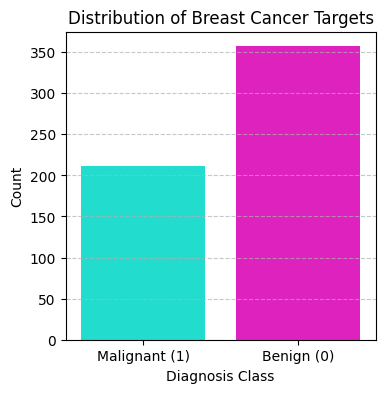

In [168]:
# Class distribution after remapping
plot_labels = y.map({1: 'Malignant (1)', 0: 'Benign (0)'})
plt.figure(figsize=(4, 4))
sns.countplot(x=plot_labels, palette={'Malignant (1)': '#03fce8', 'Benign (0)': '#fc03d3'})

plt.title('Distribution of Breast Cancer Targets')
plt.xlabel('Diagnosis Class')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### 2.4 Feature Distributions <font color="red">[2 marks]</font>

Pick 4-6 features and plot their distributions using histograms or boxplots. Look for skewness, outliers, and whether the two classes separate visually on any feature.


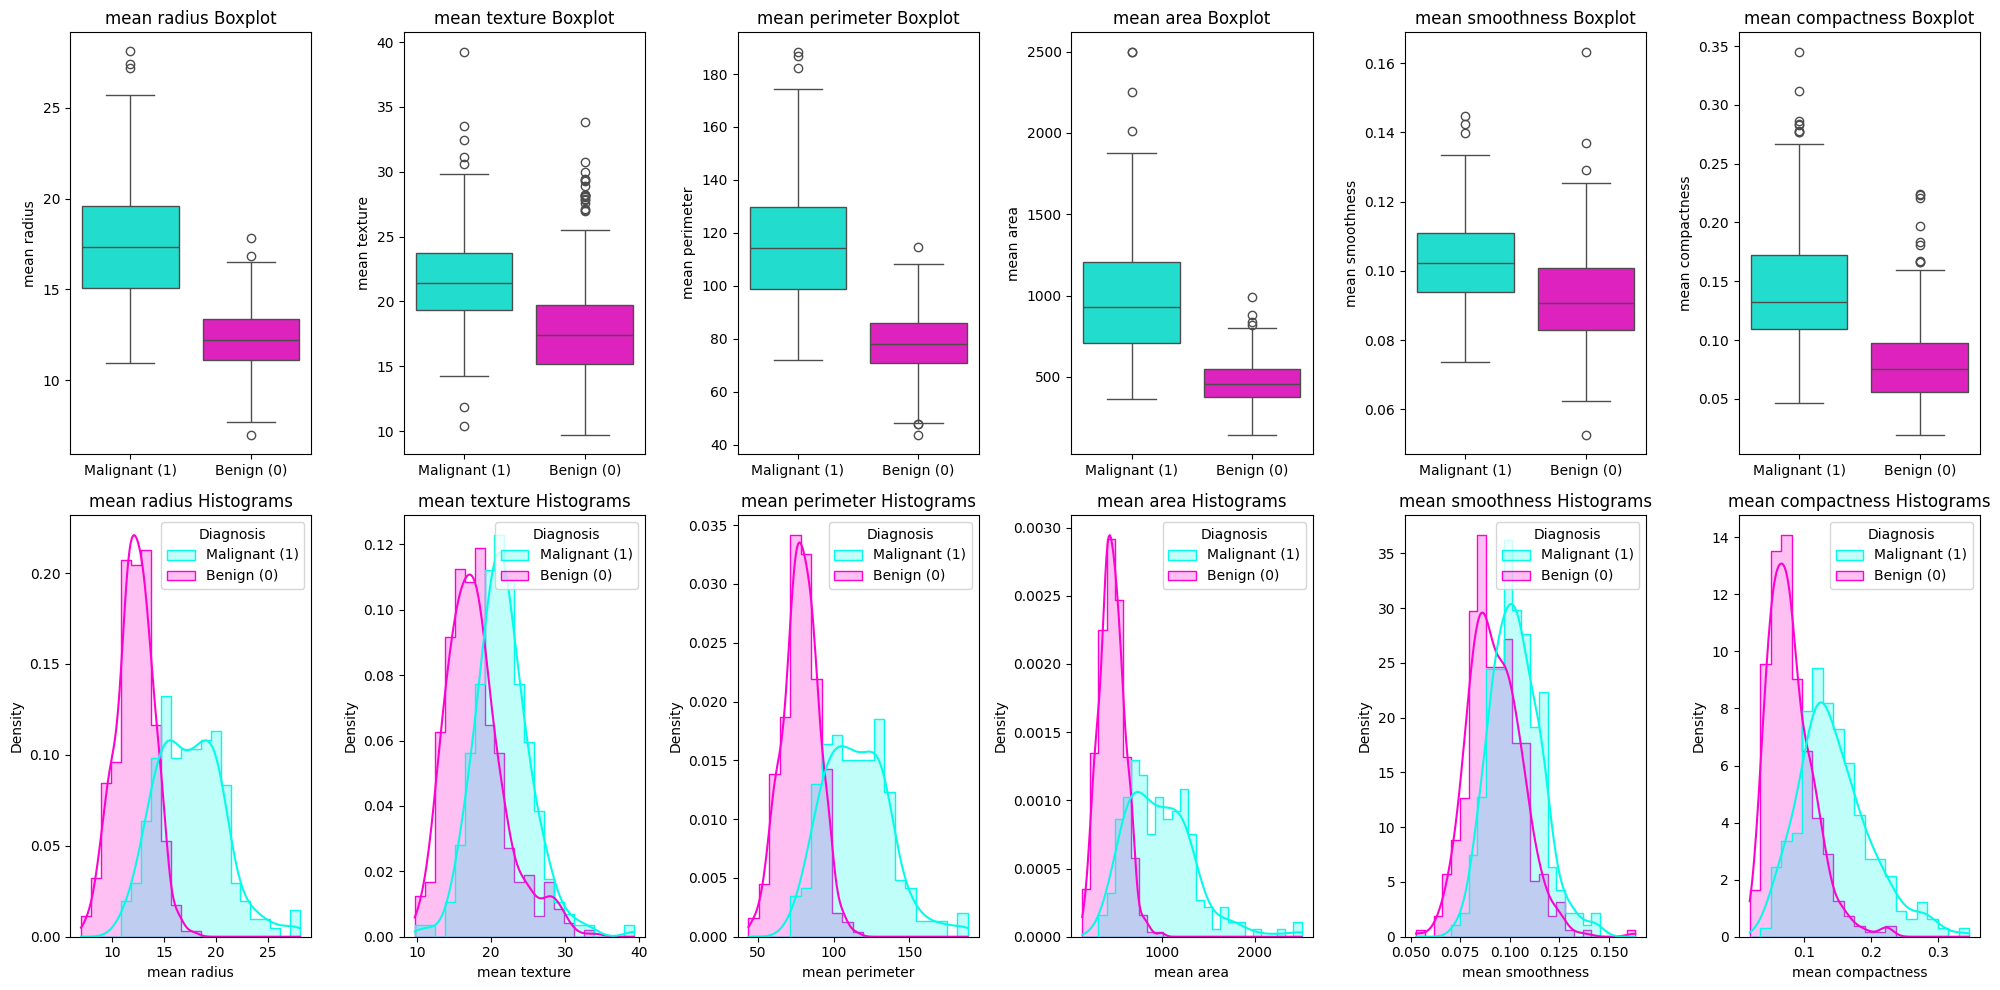

In [169]:
# Feature distributions for 6 selected features, coloured by class
features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness']

df = data.frame.copy()
df['Diagnosis'] = df['target'].map({0: 'Malignant (1)', 1: 'Benign (0)'})

fig, axes = plt.subplots(2, 6, figsize=(20, 10))
colors = {'Malignant (1)': '#03fce8', 'Benign (0)': '#fc03d3'}

for i, col in enumerate(features):
    # Row 1: Boxplots to identify outliers and median separations
    sns.boxplot(data=df, x='Diagnosis', y=col, ax=axes[0, i], palette=colors)
    axes[0, i].set_title(f'{col} Boxplot')
    axes[0, i].set_xlabel('')

    # Row 2: Histograms/KDE to identify skewness and overlapping distributions
    sns.histplot(data=df, x=col, hue='Diagnosis', ax=axes[1, i], kde=True, palette=colors, element='step', stat='density', common_norm=False)
    axes[1, i].set_title(f'{col} Histograms')

plt.tight_layout()
plt.show()


### ✍️ Interpretation Checkpoint

**[Your Answer]:** Answer these questions in 2-3 sentences each:
1. Is the dataset balanced? How might imbalance affect model training?
2. Do the features have similar scales? What does this mean for models like KNN and SVM?
3. Why is recall a better primary metric than accuracy for this problem?
4. Why must we fit the scaler on training data only and not on the full dataset? What information from the test set would leak into training if we did?


*Write your answers here:*

1. Provided data set does look imbalanced. From the plotted graphs we can see that the benign cases dominate the malignant cases. This can cause the model training to be biases towards classifing an input to benign.

2. No, as seen in section 2.2 each feature has different scale and are not comparable. For models like KNN and SVM which relies on the distance between two data points, this can result in incorrect classifications.

3. Recall is a better primary metric here because the % of correct predictions for actual postive scenarios is more important in a medical diagnosis. Accuracy should not be used here because it included the correct predictions for negative scenarios and that might reduce the visibility for postive cases.

4. We should always fit the scalar on training and test data seperately. This ensures that the model remains unaware of the boundaries of input data while being trained and produces an unbiased output during testing.


## Stage 3: Data Preprocessing and Preparation

<font color="red">**[7 marks]**</font>


### 3.1 Missing Value Audit <font color="red">[1 mark]</font>

Confirm no missing values exist. If any do, handle them with median imputation.


In [170]:
# Missing value audit
missing_in_X = X.isna().sum().sum()
missing_in_X


np.int64(0)

### 3.2 Train-Test Split <font color="red">[2 marks]</font>

Split into 70% training and 30% test using **stratified sampling** to preserve the class ratio to mitigate any slight class imbalance. Use `random_state=42`.


In [171]:
# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,          # 30% test set, 70% training set
    stratify=y,              # Critical: Preserves the target class ratio
    random_state=42          # Reproducible split
)
print("Original class ratio:\n", y.value_counts(normalize=True))
print("\nTraining class ratio:\n", y_train.value_counts(normalize=True))
print("\nTesting class ratio:\n", y_test.value_counts(normalize=True))

Original class ratio:
 target
0    0.627417
1    0.372583
Name: proportion, dtype: float64

Training class ratio:
 target
0    0.628141
1    0.371859
Name: proportion, dtype: float64

Testing class ratio:
 target
0    0.625731
1    0.374269
Name: proportion, dtype: float64


### 3.3 Feature Scaling <font color="red">[2 marks]</font>

Apply `StandardScaler`. **Fit the scaler on training data only**, then transform both train and test sets. If you fit on the full dataset, the scaler learns the mean and standard deviation of the test data, which inflates your results. That is data leakage.

> **Note:** Decision Trees split on thresholds and don't need scaling. But for consistency here, we scale for all models.


In [172]:
# Feature scaling: fit on train only, transform both

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

### 3.4 Confirm Prepared Data <font color="red">[2 marks]</font>

Print shapes of your final training and test sets. Verify the class distribution is preserved in both.


In [173]:
# Confirm prepared data
print("=== Dataset Shapes ===")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"y_train shape:        {y_train.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")
print(f"y_test shape:         {y_test.shape}\n")


=== Dataset Shapes ===
X_train_scaled shape: (398, 30)
y_train shape:        (398,)
X_test_scaled shape:  (171, 30)
y_test shape:         (171,)



## Helper: Evaluation Function

You will evaluate many models. Rather than copy-pasting the same five lines every time, define a reusable function. Call it throughout Stages 4-6.


In [174]:
# Helper function. Use this to evaluate all models consistently.
def matrix_helper(y_test, y_pred):
  # ↳ Compare y_test (truth) with y_pred (model decisions) and print the overall accuracy.
  print("Accuracy:", accuracy_score(y_test, y_pred))

  # ↳ Print a heading before the confusion matrix so the output is easy to read.
  print("\nConfusion Matrix:")

  # ↳ Compute and print the confusion matrix.
  # Rows correspond to TRUE labels and columns correspond to PREDICTED labels.
  # In this notebook the observed matrix is [[41, 2], [1, 70]].
  print(confusion_matrix(y_test, y_pred))

  # ↳ Print a heading before the detailed classification metrics.
  print("\nClassification Report:")

  # ↳ Print class-wise precision, recall, F1-score and support.
  # This tells us more than accuracy because it distinguishes different error types.
  print(classification_report(y_test, y_pred))

def evaluate_model(param_grid, estimator, X_train_scaled, y_train, scoring='recall'):
  grid = GridSearchCV(
      estimator=estimator,
      param_grid=param_grid,
      scoring=scoring,   # what metric to optimise
      cv=5,               # 5-fold cross-validation on training data
      n_jobs=-1            # use all CPU cores
  )

  # 3. Fit on training data
  grid.fit(X_train_scaled, y_train)

  # 4. Check results
  print("Best parameters:", grid.best_params_)
  print("Best CV recall:", grid.best_score_)
  best_model = grid.best_estimator_
  return best_model


## How GridSearchCV Works

If you haven't used `GridSearchCV` before, read this before moving on.

`GridSearchCV` automates hyperparameter tuning. You give it a set of parameter values to try, and it trains a model for every combination, scores each one using cross-validation, and tells you which combination won.

You can refer to the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

Here is the pattern you will repeat for every model below:

```python
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# 1. Define what parameter values to try
param_grid = {'C': [0.1, 1, 10]}

# 2. Set up GridSearchCV
grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=10000),
    param_grid=param_grid,
    scoring='recall',   # what metric to optimise
    cv=5,               # 5-fold cross-validation on training data
    n_jobs=-1            # use all CPU cores
)

# 3. Fit on training data
grid.fit(X_train_scaled, y_train)

# 4. Check results
print("Best parameters:", grid.best_params_)
print("Best CV recall:", grid.best_score_)
best_model = grid.best_estimator_

# 5. Predict on test set
y_pred = best_model.predict(X_test_scaled)
```

Every model below follows the same five steps. The only things that change are the estimator and the parameter grid.


## Stage 4: Model Training, Hyperparameter Tuning, and Evaluation

<font color="red">**[23 marks]**</font>

Train **four classifiers**, tune them, evaluate each one.

For each model:
1. Define the parameter grid
2. Run `GridSearchCV` with `scoring='recall'`, `cv=5`
3. Print the best parameters
4. Predict on the test set using the best estimator
5. Evaluate using `evaluate_model()`

> We use `scoring='recall'` because our goal is to catch malignant cases. Accuracy is misleading when classes are imbalanced.


### 4.1 Logistic Regression (Baseline) <font color="red">[5 marks]</font>

Logistic Regression with `class_weight='balanced'` to handle class imbalance.

**Hyperparameters to tune:**
- `C`: Regularisation strength. Try `[0.01, 0.1, 1, 10, 100]`
- Set `max_iter=10000` and `random_state=42`


In [175]:
# Logistic Regression with GridSearchCV
estimator = LogisticRegression(class_weight='balanced', random_state=42, max_iter=10000, n_jobs=-1)
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}
best_lr_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train)


Best parameters: {'C': 10}
Best CV recall: 0.9388505747126438


In [176]:
# Evaluate LR on test set
y_pred_lr = best_lr_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_lr)

Accuracy: 0.9707602339181286

Confusion Matrix:
[[106   1]
 [  4  60]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       107
           1       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### 4.2 K-Nearest Neighbours (KNN) <font color="red">[6 marks]</font>

[KNN](https://scikit-learn.org/stable/modules/neighbors.html) classifies a sample by majority vote of its nearest neighbours. Sensitive to feature scale, which is why we scaled the data.

**Hyperparameters to tune:**
- `n_neighbors`: Try `[3, 5, 7, 9, 11, 15]`
- `weights`: Try `['uniform', 'distance']`. Uniform gives equal votes. Distance gives closer neighbours more influence.

> Think about it: if malignant samples are sparse in a local neighbourhood, why might `weights='distance'` help?


In [177]:
# KNN with GridSearchCV
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance']
}

# 2. Initialize the base KNN model
estimator = KNeighborsClassifier()

best_knn_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train)

Best parameters: {'n_neighbors': 7, 'weights': 'uniform'}
Best CV recall: 0.925287356321839


In [178]:
# Evaluate KNN on test set
y_pred_knn = best_lr_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_knn)


Accuracy: 0.9707602339181286

Confusion Matrix:
[[106   1]
 [  4  60]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       107
           1       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### 4.3 Decision Tree <font color="red">[6 marks]</font>

[Decision Trees](https://scikit-learn.org/stable/modules/tree.html) split features at thresholds. Without constraints, they memorise training data perfectly and fail on new data. That is overfitting.

**Hyperparameters to tune:**
- `max_depth`: Try `[3, 5, 7, 10, None]`. `None` means no limit.
- `min_samples_split`: Try `[2, 5, 10]`
- `min_samples_leaf`: Try `[1, 2, 4]`
- Use `class_weight='balanced'` and `random_state=42`


In [179]:
# Decision Tree with GridSearchCV
param_grid = {
    'max_depth': [None, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 2. Initialize the base Decision Tree with balanced class weights
estimator = DecisionTreeClassifier(class_weight='balanced', random_state=42)

best_dt_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV recall: 0.9319540229885057


In [180]:
# Evaluate Decision Tree on test set
y_pred_dt = best_dt_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_dt)


Accuracy: 0.9064327485380117

Confusion Matrix:
[[101   6]
 [ 10  54]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.93       107
           1       0.90      0.84      0.87        64

    accuracy                           0.91       171
   macro avg       0.90      0.89      0.90       171
weighted avg       0.91      0.91      0.91       171



### 4.4 Support Vector Machine (SVM) <font color="red">[6 marks]</font>

[SVMs](https://scikit-learn.org/stable/modules/svm.html) find the hyperplane that separates classes with the widest margin. With kernel functions, they can model non-linear boundaries.

**Hyperparameters to tune:**
- `C`: Try `[0.1, 1, 10]`
- `kernel`: Try `['linear', 'rbf']`. Linear for linearly separable data, RBF for non-linear.
- `gamma`: Try `['scale', 'auto']` (matters for RBF kernel)
- Use `class_weight='balanced'`, `random_state=42`, and `probability=True`

> **Why `probability=True`?** We need `predict_proba()` for threshold tuning in Stage 6.


In [181]:
# SVM with GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['linear', 'rbf']
}

estimator = SVC(class_weight='balanced', random_state=42, probability=True)
best_svm_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train)


Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV recall: 0.9519540229885057


In [182]:
# Evaluate SVM on test set
y_pred_svm = best_svm_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_svm)


Accuracy: 0.9824561403508771

Confusion Matrix:
[[106   1]
 [  2  62]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       107
           1       0.98      0.97      0.98        64

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



## Stage 5: Model Comparison

<font color="red">**[9 marks]**</font>


### 5.1 Build a Comparison Table <font color="red">[3 marks]</font>

Create a DataFrame comparing all four models on the **test set**:
- Accuracy
- Recall (for malignant class)
- Precision (for malignant class)
- F1-Score (for malignant class)
- Number of False Negatives (from confusion matrix)

> **Hint:** A false negative is a malignant case predicted as benign. In the confusion matrix, it sits at position `[1][0]` when malignant = 1.


In [183]:
from sklearn.metrics import precision_recall_fscore_support

# Comparison table for all 4 models
model_predictions = {
    'Logistic Regression': y_pred_lr,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'SVM': y_pred_svm
}


malignant_label = 1

metrics_list = []

for name, preds in model_predictions.items():

    acc = accuracy_score(y_test, preds)

    # Precision, Recall, and F1 specifically for the Malignant class
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, preds, average=None, labels=[malignant_label]
    )

    # Calculate confusion matrix to pull False Negatives
    # In a binary CM, false negatives are items where truth=malignant but pred=benign
    cm = confusion_matrix(y_test, preds)

    # Safe extraction of False Negatives depending on class positioning
    false_negatives = cm[1, 0]

    metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Malignant Precision': precision[0],
        'Malignant Recall': recall[0],
        'Malignant F1-Score': f1[0],
        'False Negatives (FN)': false_negatives
    })

# 4. Generate the comparison DataFrame
comparison_df = pd.DataFrame(metrics_list).set_index('Model')

# Format columns nicely for viewing
formatted_df = comparison_df.copy()
for col in ['Accuracy', 'Malignant Precision', 'Malignant Recall', 'Malignant F1-Score']:
    formatted_df[col] = formatted_df[col].map('{:.2%}'.format)

print(formatted_df)



                    Accuracy Malignant Precision Malignant Recall  \
Model                                                               
Logistic Regression   97.08%              98.36%           93.75%   
KNN                   97.08%              98.36%           93.75%   
Decision Tree         90.64%              90.00%           84.38%   
SVM                   98.25%              98.41%           96.88%   

                    Malignant F1-Score  False Negatives (FN)  
Model                                                         
Logistic Regression             96.00%                     4  
KNN                             96.00%                     4  
Decision Tree                   87.10%                    10  
SVM                             97.64%                     2  


### 5.2 Visualise Comparison <font color="red">[2 marks]</font>

Create a grouped bar chart comparing Recall and Precision across all four models.


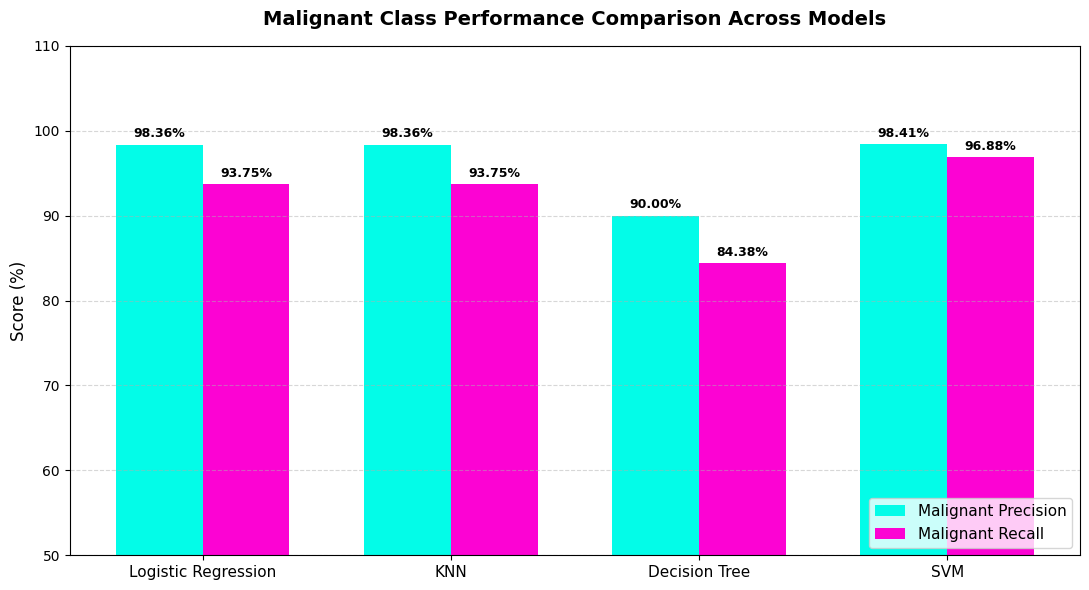

In [184]:
# Grouped bar chart: Recall and Precision
plot_df = comparison_df.reset_index()

models = plot_df['Model'].tolist()

precision_scores = (plot_df['Malignant Precision'] * 100).tolist()
recall_scores = (plot_df['Malignant Recall'] * 100).tolist()

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

rects1 = ax.bar(x - width/2, precision_scores, width, label='Malignant Precision', color='#03fce8')
rects2 = ax.bar(x + width/2, recall_scores, width, label='Malignant Recall', color='#fc03d3')

ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Malignant Class Performance Comparison Across Models', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(50, 110)
ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()



### 5.3 Cross-Validation Stability <font color="red">[2 marks]</font>

For **all four models**, run 5-fold stratified [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) on the **training set** using `cross_val_score` with `scoring='recall'`. Print the mean and standard deviation of recall for each.

> **Why this matters:** High recall on one split means nothing if the model collapses on another. Stability tells you whether you can trust the number.

> **A caveat:** You are running `cross_val_score` on already-tuned estimators. This is a quick stability check, not a substitute for nested cross-validation. Good enough for a practice exercise.


In [185]:
# Cross-validation stability for all 4 models

models_dict = {
    'Logistic Regression': best_lr_model,
    'KNN': best_knn_model,
    'Decision Tree': best_dt_model,
    'SVM': best_svm_model
}


for name, model in models_dict.items():
    scores = cross_val_score(
        estimator=model,
        X=X_train_scaled,
        y=y_train,
        cv=5,
        scoring='recall',
        n_jobs=-1
    )

    mean_recall = scores.mean()
    std_recall = scores.std()

    print(f"{name}:")
    print(f"Mean Recall: {mean_recall:.2%}")
    print(f"Std Dev:     {std_recall:.2%}\n")


Logistic Regression:
Mean Recall: 93.89%
Std Dev:     2.62%

KNN:
Mean Recall: 92.53%
Std Dev:     7.36%

Decision Tree:
Mean Recall: 93.20%
Std Dev:     4.85%

SVM:
Mean Recall: 95.20%
Std Dev:     6.40%



### 5.4 Feature Importance <font color="red">[2 marks]</font>

Knowing *which features drive predictions* matters as much as the predictions themselves.

- Extract **feature importances** from your best Decision Tree (`.feature_importances_`) or **coefficients** from Logistic Regression (`.coef_[0]`)
- Plot the **top 10 most important features** as a horizontal bar chart


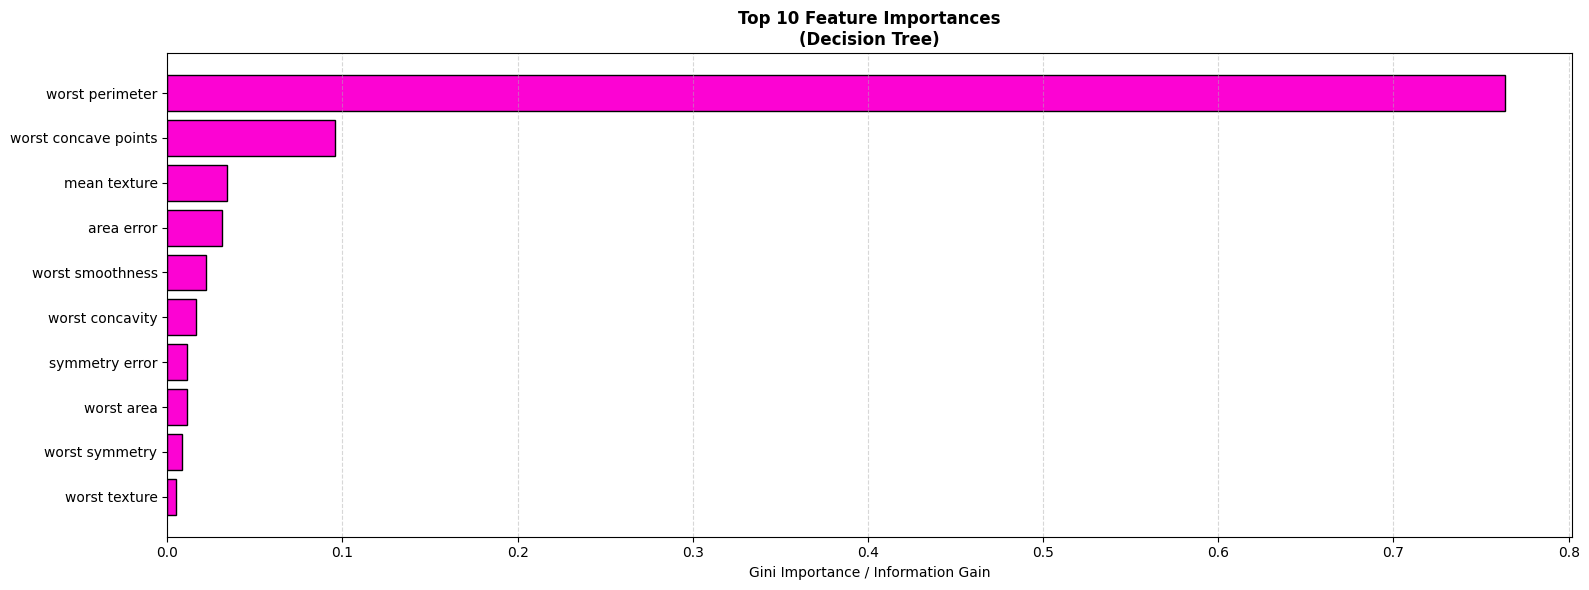

In [186]:
# Feature importance from Decision Tree
dt_importances = best_dt_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Decision Tree Importance': dt_importances
})

plt.figure(figsize=(16, 6))

top_10_dt = importance_df.sort_values(by='Decision Tree Importance', ascending=True).tail(10)
plt.barh(top_10_dt['Feature'], top_10_dt['Decision Tree Importance'], color='#fc03d3', edgecolor='black')
plt.title('Top 10 Feature Importances\n(Decision Tree)', fontsize=12, fontweight='bold')
plt.xlabel('Gini Importance / Information Gain')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## Stage 6: Final Model Selection

<font color="red">**[5 marks]**</font>


### 6.1 Threshold Tuning <font color="red">[2 marks]</font>

By default, classifiers use a probability threshold of 0.5 to assign classes. For medical diagnosis, we can lower this threshold to catch more malignant cases (higher recall) at the cost of more false positives (lower precision).

**Steps:**
1. Create a **stratified validation split from your training data** (70/30 from `X_train_scaled`). Do not touch the test set for this.
2. Retrain your best model on the inner training portion
3. Get predicted probabilities on the validation portion using `predict_proba()`
4. Plot the **precision-recall curve**
5. Find a threshold where recall ≥ 0.95

> **Why not tune on the test set?** If you use the test set to pick a threshold, your final evaluation on that same test set is no longer honest. The test set becomes a tuning surface, and your reported metrics are optimistic.


In [187]:
# Threshold tuning on a VALIDATION split (not test set)

# Step 1: Create inner split from training data
X_inner_train, X_val, y_inner_train, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.30,
    stratify=y_train,
    random_state=42
)

# Step 2: Retrain best model (SVM) on inner training set
best_svm = SVC(C=1, kernel='rbf', gamma='scale', class_weight='balanced', probability=True, random_state=42)
best_svm.fit(X_inner_train, y_inner_train)

# Step 3: Get predicted probabilities on validation set
y_scores_malignant = best_svm.predict_proba(X_val)[:, 1]

# Step 4: Plot precision-recall curve
precisions, recalls, thresholds = precision_recall_curve(y_val, y_scores_malignant, pos_label=1)

# Step 5: Find threshold where recall >= 0.95
valid_indices = np.where(recalls[:-1] >= 0.95)[0]  # Exclude the last placeholder value in recalls
best_index = valid_indices[np.argmax(precisions[valid_indices])]

chosen_threshold = thresholds[best_index]
chosen_precision = precisions[best_index]
chosen_recall = recalls[best_index]

print("=== Operational Threshold Analysis (Malignant Class) ===")
print(f"Optimal Probability Threshold: {chosen_threshold:.4f}")
print(f"Resulting Validation Recall:    {chosen_recall:.2%}")
print(f"Resulting Validation Precision: {chosen_precision:.2%}\n")


=== Operational Threshold Analysis (Malignant Class) ===
Optimal Probability Threshold: 0.2408
Resulting Validation Recall:    95.56%
Resulting Validation Precision: 89.58%



### 6.2 Final Recommendation <font color="red">[3 marks]</font>

**[Your Answer]:** Answer the following. Cite specific numbers from your results.

1. Which model do you recommend and why? Reference its recall, false negative count, and cross-validation stability.
2. How many false negatives does it produce on the test set? Is this clinically acceptable?
3. What is one specific limitation of your analysis? (Not "more data." Be concrete, e.g., "the dataset has only 569 samples, which limits the reliability of cross-validation estimates.")


*Write your answers here:*

1. I recommend SVM model since it has the highest recall value.

2. It produced 2 FN. However compared to other models SVM produced the least FN count. It is not clinically acceptable though

3. Dataset was an imbalanced dataset as we noticed in the beginning. I believe that contributed to the FN classifications.


---
# PART 2: Multiclass Classification, Wine Dataset

## Context

The Wine dataset contains chemical analysis results of wines from the same region of Italy, grown from **three different cultivars** (grape varieties). The task: predict the cultivar (class 0, 1, or 2) based on 13 chemical attributes like alcohol content, malic acid, and flavanoids.

**Why Macro-F1 matters here:** No single wine class is more "dangerous" to misclassify. All three matter equally. Macro-averaged F1-score treats each class the same regardless of size.


## Stage 1: Data and Package Loading

<font color="red">**[2 marks]**</font>

Load the Wine dataset from `sklearn.datasets`. Convert to a DataFrame. Separate features and target. Import `MLPClassifier`.


In [188]:
# Pre-imported for Part 2
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import load_wine

# Load wine dataset
wine_data = load_wine(as_frame=True)

# Convert to DataFrame
wine_df = wine_data.frame

# Separate features and target
X = wine_df.drop('target', axis=1)
y = wine_df['target']


## Stage 2: Data Understanding

<font color="red">**[6 marks]**</font>


### 2.1 Basic Inspection <font color="red">[2 marks]</font>

Display the shape, first few rows, data types, and check for missing values.


In [189]:
# Inspect the wine dataset
print(f"Shape: {wine_df.shape}")
print(f"First few rows:\n{wine_df.head()}")
print(f"Data types:\n{wine_df.dtypes}")

Shape: (178, 14)
First few rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_win

### 2.2 Class Distribution <font color="red">[2 marks]</font>

How many wines in each class? Visualise with a bar plot.


Text(0.5, 1.0, 'Wine Class Distribution')

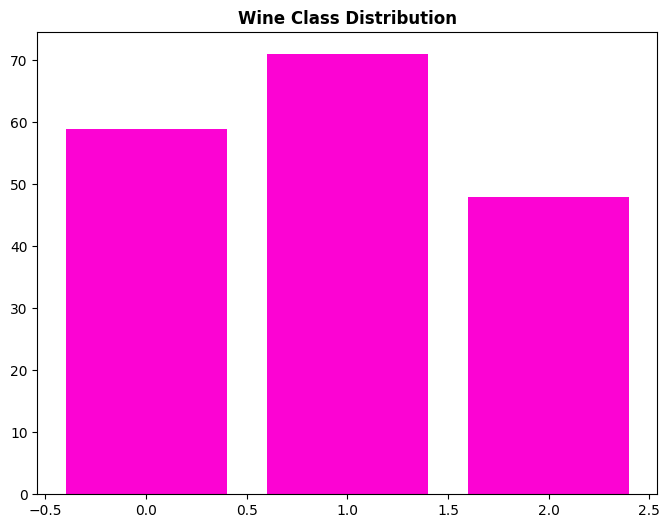

In [190]:
# Wine class distribution
class_counts = wine_df['target'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8, 6))
plt.bar(class_counts.index, class_counts.values, color='#fc03d3')
plt.title('Wine Class Distribution', fontsize=12, fontweight='bold')

### 2.3 Feature Analysis <font color="red">[2 marks]</font>

Look at the feature ranges using `.describe()`. Some features range in the hundreds, others below 1. Then plot a **correlation heatmap** to see which features move together.


          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.9

<Axes: >

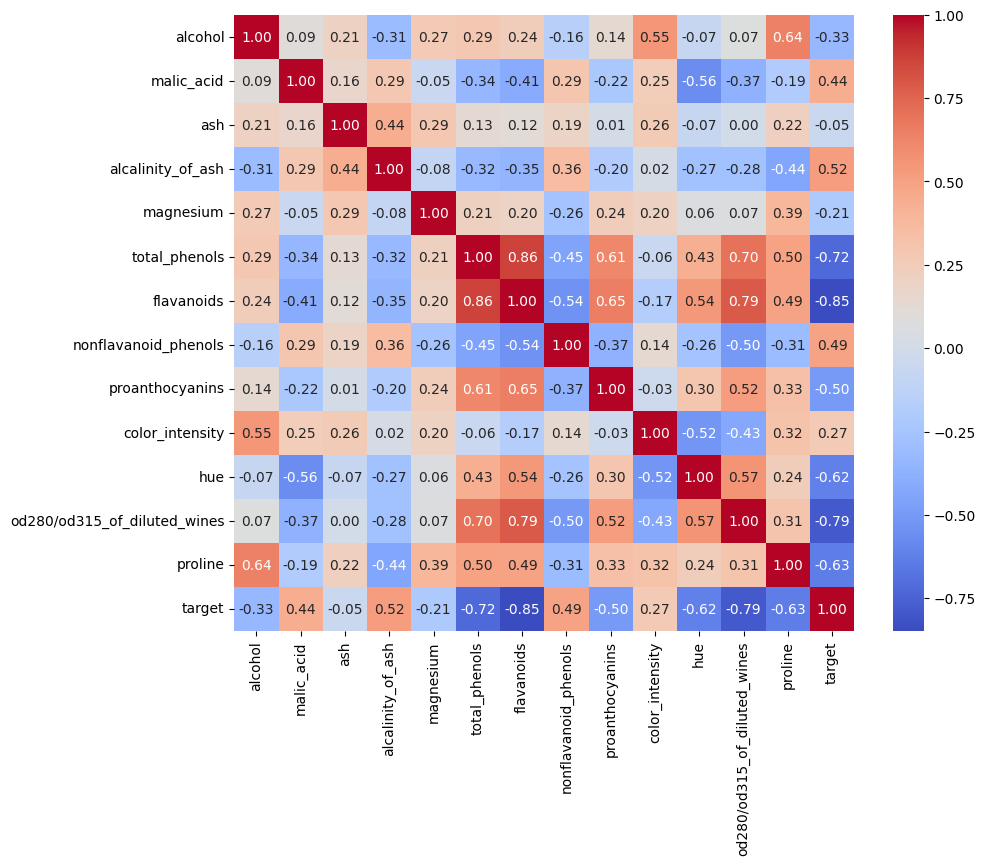

In [191]:
# Summary statistics
print(wine_df.describe())

# Correlation heatmap
corr_matrix = wine_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")

### ✍️ Interpretation Checkpoint

**[Your Answer]:**
1. Are the three wine classes roughly balanced?
2. Looking at the feature ranges, do some features dominate others in scale? What does this imply for models like KNN and SVM?


*Write your answers here:*

1. Yes, dataset is roughly balanced

2. This has same issue as above binary classification dataset, when few features have more priority in heatmap, KNN and SVM would become biased towards those features. We need to scale these features


## Stage 3: Data Preprocessing

<font color="red">**[4 marks]**</font>


### 3.1 Split and Scale <font color="red">[2 marks]</font>

Stratified train-test split (70-30, `random_state=42`), then `StandardScaler` fit on training data only. Stratification for handling any slight class imbalance in the data.

> **Reminder:** Decision Trees don't need scaling, but KNN, SVM, MLP, and Logistic Regression all do. We scale for all models here.


In [192]:
# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

In [193]:
# Scale features: fit on train, transform both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 3.2 Verify Preparation <font color="red">[2 marks]</font>

Print shapes and class distributions for both splits.


In [194]:
# Verify preparation
print(f"Training data shape: {X_train_scaled.shape}")
print(f"Test data shape:     {X_test_scaled.shape}\n")

Training data shape: (124, 13)
Test data shape:     (54, 13)



## Stage 4: Model Training and Hyperparameter Tuning

<font color="red">**[20 marks]**</font>

Train **five classifiers** on the wine dataset. Use `GridSearchCV` with `scoring='f1_macro'` and `cv=5` for each. Use the `evaluate_model()` helper from Part 1.

> **Key difference from Part 1:** We optimise for `f1_macro` instead of `recall`, because all classes matter equally.


### 4.1 Logistic Regression <font color="red">[3 marks]</font>

**Hyperparameters:**
- `C`: `[0.01, 0.1, 1, 10]`
- `max_iter`: `10000`
- `random_state`: `42`


In [195]:
# Logistic Regression for Wine
estimator = LogisticRegression(class_weight='balanced', random_state=42, max_iter=10000, n_jobs=-1)
param_grid = {'C': [0.01, 0.1, 1, 10]}
best_lr_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train, scoring='f1_macro')

y_pred_lr = best_lr_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_lr)

Best parameters: {'C': 1}
Best CV recall: 0.9834098065677013
Accuracy: 0.9814814814814815

Confusion Matrix:
[[18  0  0]
 [ 1 20  0]
 [ 0  0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        18
           1       1.00      0.95      0.98        21
           2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



### 4.2 K-Nearest Neighbours <font color="red">[3 marks]</font>

**Hyperparameters:**
- `n_neighbors`: `[3, 5, 7, 9, 11]`
- `weights`: `['uniform', 'distance']`


In [196]:
# KNN for Wine
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance']
}

# 2. Initialize the base KNN model
estimator = KNeighborsClassifier()

best_knn_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train, scoring='f1_macro')

y_pred_knn = best_knn_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_knn)

Best parameters: {'n_neighbors': 11, 'weights': 'uniform'}
Best CV recall: 0.9775988992088063
Accuracy: 0.9629629629629629

Confusion Matrix:
[[18  0  0]
 [ 0 19  2]
 [ 0  0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       1.00      0.90      0.95        21
           2       0.88      1.00      0.94        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



### 4.3 Decision Tree <font color="red">[3 marks]</font>

**Hyperparameters:**
- `max_depth`: `[3, 5, 7, 10, None]`
- `min_samples_split`: `[2, 5, 10]`
- `min_samples_leaf`: `[1, 2, 4]`
- `random_state`: `42`


In [197]:
# Decision Tree for Wine
param_grid = {
    'max_depth': [None, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 2. Initialize the base Decision Tree with balanced class weights
estimator = DecisionTreeClassifier(class_weight='balanced', random_state=42)

best_dt_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train, scoring='f1_macro')

y_pred_dt = best_dt_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_dt)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV recall: 0.92417965476789
Accuracy: 0.9444444444444444

Confusion Matrix:
[[16  2  0]
 [ 1 20  0]
 [ 0  0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.91        18
           1       0.91      0.95      0.93        21
           2       1.00      1.00      1.00        15

    accuracy                           0.94        54
   macro avg       0.95      0.95      0.95        54
weighted avg       0.95      0.94      0.94        54



### 4.4 Support Vector Machine <font color="red">[3 marks]</font>

**Hyperparameters:**
- `C`: `[0.1, 1, 10]`
- `kernel`: `['linear', 'rbf']`
- `gamma`: `['scale', 'auto']`
- `random_state`: `42`


In [198]:
# SVM for Wine
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['linear', 'rbf']
}

estimator = SVC(class_weight='balanced', random_state=42, probability=True)
best_svm_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train, scoring='f1_macro')

y_pred_svm = best_svm_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_svm)


Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV recall: 0.992046783625731
Accuracy: 0.9814814814814815

Confusion Matrix:
[[18  0  0]
 [ 0 21  0]
 [ 0  1 14]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.95      1.00      0.98        21
           2       1.00      0.93      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



### 4.5 Multi-Layer Perceptron (MLP) <font color="red">[8 marks]</font>

The MLP is a neural network. Unlike the previous models, you control the **architecture**: how many layers, how many neurons per layer.

**Hyperparameters to tune:**
- `hidden_layer_sizes`: Try `[(50,), (100,), (50, 50), (100, 50)]`. Each tuple defines layer widths.
- `activation`: Try `['relu', 'tanh']`. The non-linear function at each neuron.
- `alpha`: Try `[0.0001, 0.001, 0.01]`. L2 regularisation to prevent overfitting.
- Set `max_iter=2000`, `random_state=42`, and `early_stopping=True`

> **What is early stopping?** It monitors validation performance during training and stops when performance plateaus. Without it, the network keeps training until it memorises the data.


In [199]:
# MLP for Wine
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01]
}

estimator = MLPClassifier(
    max_iter=2000,
    random_state=42,
    early_stopping=True
)

best_mlp_model = evaluate_model(param_grid, estimator, X_train_scaled, y_train, scoring='f1_macro')


Best parameters: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (100,)}
Best CV recall: 0.9136279016646496


In [200]:
# Evaluate MLP on test set

y_pred_mlp = best_mlp_model.predict(X_test_scaled)
matrix_helper(y_test, y_pred_mlp)


Accuracy: 0.8518518518518519

Confusion Matrix:
[[18  0  0]
 [ 5 13  3]
 [ 0  0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88        18
           1       1.00      0.62      0.76        21
           2       0.83      1.00      0.91        15

    accuracy                           0.85        54
   macro avg       0.87      0.87      0.85        54
weighted avg       0.88      0.85      0.84        54



### ✍️ MLP Interpretation

**[Your Answer]:**
1. What architecture (hidden layer sizes) performed best? Why do you think that configuration won?
2. Did the MLP outperform the classical models? By how much in macro-F1?
3. What role does `alpha` (regularisation) play? What happens if it is set too high? Too low?


*Write your answers here:*

1. 'hidden_layer_sizes': (100,) performed best, the layer depth is large enough to accomodat the feature

2. No it does not.

3. alpha valu regularizes the large weights while training. If set too high, it might cause underfitting


## Stage 5: Model Comparison

<font color="red">**[8 marks]**</font>


### 5.1 Comparison Table <font color="red">[3 marks]</font>

Create a DataFrame comparing all five models on the **test set**:
- Accuracy
- Macro-Precision
- Macro-Recall
- Macro-F1-Score


In [201]:
# Comparison table for all 5 wine models
from sklearn.metrics import precision_recall_fscore_support

# Comparison table for all 4 models
model_predictions = {
    'Logistic Regression': y_pred_lr,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'SVM': y_pred_svm,
    'MLP': y_pred_mlp
}


macro_metrics_list = []

for name, preds in model_predictions.items():
    # Calculate overall subset accuracy
    acc = accuracy_score(y_test, preds)

    # Calculate macro-averaged metrics across both target classes
    macro_prec, macro_rec, macro_f1, _ = precision_recall_fscore_support(
        y_test, preds, average='macro'
    )

    macro_metrics_list.append({
        'Model': name,
        'Accuracy': acc,
        'Macro-Precision': macro_prec,
        'Macro-Recall': macro_rec,
        'Macro-F1-Score': macro_f1
    })

# 3. Construct and format the comparison DataFrame
five_model_df = pd.DataFrame(macro_metrics_list).set_index('Model')

# Apply a clean percentage format for presentation
formatted_five_model_df = five_model_df.copy()
for col in formatted_five_model_df.columns:
    formatted_five_model_df[col] = formatted_five_model_df[col].map('{:.2%}'.format)

print(formatted_five_model_df)



                    Accuracy Macro-Precision Macro-Recall Macro-F1-Score
Model                                                                   
Logistic Regression   98.15%          98.25%       98.41%         98.29%
KNN                   96.30%          96.08%       96.83%         96.25%
Decision Tree         94.44%          95.01%       94.71%         94.82%
SVM                   98.15%          98.48%       97.78%         98.08%
MLP                   85.19%          87.20%       87.30%         85.06%


### 5.2 Visualise Comparison <font color="red">[2 marks]</font>

Bar chart comparing Macro-F1 scores across all five models.


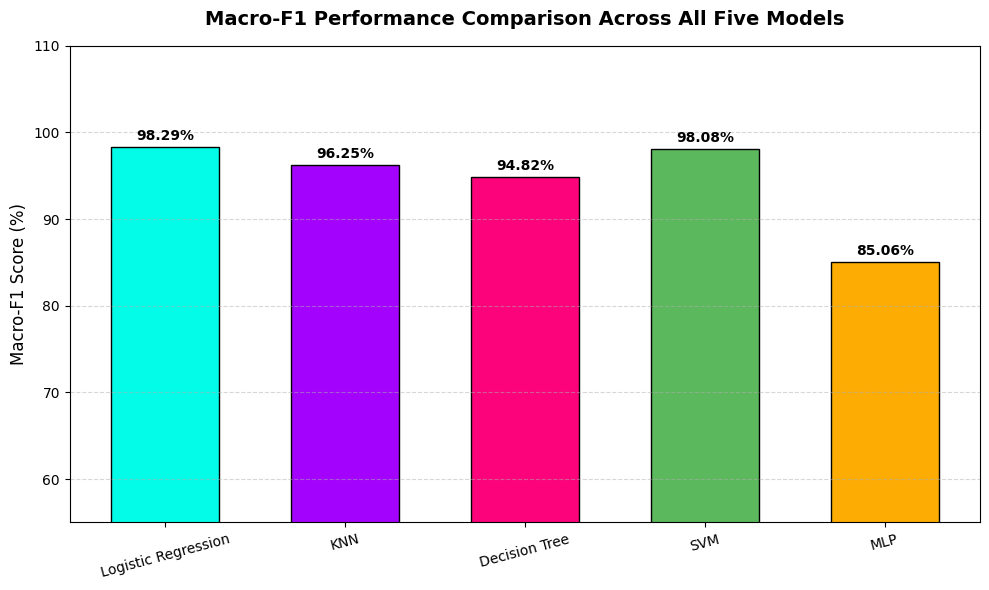

In [202]:
# Macro-F1 bar chart

plot_five_df = five_model_df.reset_index()

models = plot_five_df['Model'].tolist()
macro_f1_scores = (plot_five_df['Macro-F1-Score'] * 100).tolist()

plt.figure(figsize=(10, 6))
bars = plt.bar(models, macro_f1_scores, color=['#03fce8', '#a303fc', '#fc037b', '#5cb85c', '#fcac03'], edgecolor='black', width=0.6)

plt.ylabel('Macro-F1 Score (%)', fontsize=12)
plt.title('Macro-F1 Performance Comparison Across All Five Models', fontsize=14, fontweight='bold', pad=15)
plt.xticks(fontsize=10, rotation=15)
plt.ylim(55, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()



### 5.3 Cross-Validation Stability <font color="red">[3 marks]</font>

For **all five models**, run 5-fold cross-validation with `scoring='f1_macro'` on the training set. Print the mean and standard deviation for each.


In [203]:
# Cross-validation stability for all 5 wine models
models_dict = {
    'Logistic Regression': best_lr_model,
    'KNN': best_knn_model,
    'Decision Tree': best_dt_model,
    'SVM': best_svm_model,
    'MLP': best_mlp_model
}


for name, model in models_dict.items():
    scores = cross_val_score(
        estimator=model,
        X=X_train_scaled,
        y=y_train,
        cv=5,
        scoring='f1_macro',
        n_jobs=-1
    )

    mean_recall = scores.mean()
    std_recall = scores.std()

    print(f"{name}:")
    print(f"Mean Recall: {mean_recall:.2%}")
    print(f"Std Dev:     {std_recall:.2%}\n")

Logistic Regression:
Mean Recall: 98.34%
Std Dev:     2.03%

KNN:
Mean Recall: 97.76%
Std Dev:     1.84%

Decision Tree:
Mean Recall: 92.42%
Std Dev:     6.70%

SVM:
Mean Recall: 99.20%
Std Dev:     1.59%

MLP:
Mean Recall: 91.36%
Std Dev:     5.91%



### ✍️ Classical vs Neural Comparison

**[Your Answer]:**
1. Which classical model performed best on macro-F1? Why might that be?
2. Did the MLP beat the classical models by a clear margin, or was the gap small?
3. When would you choose a simpler model like Logistic Regression over the MLP, even if the MLP scores slightly higher?


*Write your answers here:*

1. SVM performed best on macro-F1

2. no, gap was significant

3. LR is more simpler model than MLP


## Stage 6: Final Recommendation

<font color="red">**[5 marks]**</font>


### 6.1 Final Model Selection <font color="red">[3 marks]</font>

**[Your Answer]:**
1. Which model do you recommend as the best **classical** model for the wine dataset? Cite its macro-F1 score.
2. Which model do you recommend as the best **overall** model? Consider performance vs interpretability.
3. If a winemaker wanted to understand *why* a wine was classified as a certain cultivar, which model would you recommend and why?


*Write your answers here:*

1. SVM

2. SVM

3. SVM

### 6.2 Underfitting vs Overfitting Study <font color="red">[2 marks]</font>

Train three Decision Tree variants on the wine dataset:
1. `max_depth=1` with `random_state=42` (too simple, underfits)
2. `max_depth=None` with `random_state=42` (no constraints, overfits)
3. Your best tuned tree from Stage 4

For each, print the **training accuracy** and **test accuracy**. Look at the gap.


In [205]:
# Overfitting study: 3 Decision Tree variants
wine = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, test_size=0.30, stratify=wine.target, random_state=42
)

dt_1 = DecisionTreeClassifier(max_depth=1, random_state=42)
dt_2 = DecisionTreeClassifier(max_depth=None, random_state=42)
dt_3 = best_dt_model

for name, model in [('DT 1', dt_1), ('DT 2', dt_2), ('DT 3', dt_3)]:
    model.fit(X_train, y_train)

    # Generate predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate performance scores
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    generalization_gap = train_acc - test_acc

    print(f"{name}:")
    print(f"  • Training Accuracy: {train_acc:.2%}")
    print(f"  • Test Accuracy:     {test_acc:.2%}")
    print(f"  • Generalization Gap: {generalization_gap:.2%}\n")



DT 1:
  • Training Accuracy: 66.13%
  • Test Accuracy:     61.11%
  • Generalization Gap: 5.02%

DT 2:
  • Training Accuracy: 100.00%
  • Test Accuracy:     96.30%
  • Generalization Gap: 3.70%

DT 3:
  • Training Accuracy: 100.00%
  • Test Accuracy:     94.44%
  • Generalization Gap: 5.56%



### ✍️ Underfitting vs Overfitting

**[Your Answer]:**
1. Which variant underfits? How can you tell from the train/test accuracy?
2. Which variant overfits? What is the gap between train and test accuracy?
3. How does the tuned model sit between these two extremes?


*Write your answers here:*

1. ***your answer here***

2. ***your answer here***

3. ***your answer here***


---
## Indicative Mark Summary

> **Reminder:** These marks are for self-assessment only. They do not count towards your final grade.

| Section | Topic | Marks |
|---------|-------|-------|
| **Part 1** | | **55** |
| Stage 1 | Data Loading | 3 |
| Stage 2 | Data Understanding + Interpretation | 8 |
| Stage 3 | Preprocessing | 7 |
| Helper + Tutorial | Evaluation Function, GridSearchCV Walkthrough | 0 |
| Stage 4 | Model Training and Tuning (4 models) | 23 |
| Stage 5 | Model Comparison + Feature Importance | 9 |
| Stage 6 | Final Model Selection | 5 |
| **Part 2** | | **45** |
| Stage 1 | Data Loading | 2 |
| Stage 2 | Data Understanding + Interpretation | 6 |
| Stage 3 | Preprocessing | 4 |
| Stage 4 | Model Training and Tuning (5 models, incl. MLP) | 20 |
| Stage 5 | Model Comparison | 8 |
| Stage 6 | Final Recommendation | 5 |
| | **Total** | **100** |

---
*End of Practice Assignment*
